<center>
<img src="../images/fscampus_small2.png" width="1200"/>
</center>

<center>

# Investments

***Finance 2 - BFIN***

**Dr. Omer Cayirli**

Lecturer in Empirical Finance

omer_cayirli@uncbusiness.net
</center>

---

## Extra Session

---


### Outline

* Black-Scholes Option Pricing Model

* APT and Multifactor Models

* Binomial Option Pricing: Two Periods

---


### Black-Scholes Option Pricing Model
* Key assumptions
  
  * There are no arbitrage opportunities.
  
  * Underlying asset is a traded security, and investors can trade continuously.
  
  * The option to be priced is European.
  
  * Constant volatility, with no jumps. In the corresponding binomial approximation, $u$ and $d$ remain constant across equal-length steps.
  
  * No transaction costs or taxes, securities perfectly divisible, no portfolio restrictions, investors are price-takers.

* Continuous trading assumption
  
  * When markets are open, we can trade as we wish, so it is a good approximation.
  
  * But markets do close, so continuous trading is not ideal.

---





### Black-Scholes Option Pricing Model

**Black-Scholes Price of a Call Option on a Non-Dividend-Paying Stock**
$$ C_t = S_t \times N(d_1) - PV(K) \times N(d_2) $$

$\quad\text{where:} $

$$ PV(K) = Ke^{-r_f(T-t)} $$

$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

**Black-Scholes Price of a Put Option on a Non-Dividend-Paying Stock**

$$
P_t = PV(K)[1 - N(d_2)] - S_t[1 - N(d_1)]
$$

**Default Notation**

* $\mathbf{S_t}$ : Value of the underlying asset at date $t$;
* $\mathbf{K}$ : Strike price of the option;
* $\mathbf{r_f}$ : Risk-free rate (annual, continuously compounded);
* $\mathbf{\sigma}$ : Volatility (in annual terms), i.e. squared root of the variance;
* $\mathbf{T}$ : Maturity, so at date $t$, $T - t$ is time to maturity in years.
* $\mathbf{N(d)}$ : The cumulative normal distribution
---



### Black-Scholes Option Pricing Model

**Black-Scholes Price of a Call Option on a Non-Dividend-Paying Stock**
$$ C_t = S_t \times N(d_1) - PV(K) \times N(d_2) \quad \text{where} $$
$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

**Black-Scholes Price of a Put Option on a Non-Dividend-Paying Stock**
$$ P_t = PV(K)[1 - N(d_2)] - S_t[1 - N(d_1)] $$

* The value of a call is a weighted difference of the present value of its potential benefits, $S_t$, and the present value of its potential costs $PV(K)$ where the weights $N(d_1)$ and $N(d_1 - \sigma\sqrt{T-t})$ are in $(0, 1)$.

* The value of a put is a weighted difference of the present value of its potential benefits, $PV(K)$, and the present value of its potential costs, $S_t$, where the weights $[1 - N(d_2)]$ and $[1 - N(d_1)]$ are in $(0, 1)$.

$$ C_t = S_t \times \underbrace{N(d_1)}_{\Delta} - \underbrace{PV(K) \times N(d_2)}_{\text{Borrowing}} \implies C_t = \text{Asset Price} \times \text{Delta} + \text{Cash Position} $$

---



### Black-Scholes Option Pricing Model

* The standard normal cumulative distribution $N(d)$
  * $N(d)=\Pr(Z\le d)$ for $Z\sim N(0,1)$: Area under the standard normal curve to the left of $d$.
  * $0<N(d)<1$ for finite $d$; approaches 0 and 1 in the tails.
  * Excel: `=NORM.S.DIST(d,TRUE)`.

$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

* Volatility follows the square-root-of-time rule when log returns are uncorrelated and have constant variance.
  * Monthly to annual: $\sigma_a=\sqrt{12}\sigma_m$.
  * Weekly to annual: $\sigma_a=\sqrt{52}\sigma_w$.
  * Daily to annual: $\sigma_a=\sqrt{250}\sigma_d$, using 250 trading days per year.

---


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def normal_bs_values(S, K, tau, r_pct, sigma_pct):
    """Black-Scholes inputs for positive time and volatility; annual cc rate."""
    if not all(math.isfinite(x) for x in (S,K,tau,r_pct,sigma_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if min(S,K,tau,sigma_pct)<=0:
        raise ValueError("Stock price, strike, time and volatility must be positive.")
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    gap=sigma*math.sqrt(tau)
    term=(math.log(S/K)+r*tau)/gap
    d1=term+gap/2; d2=d1-gap
    n1,n2=norm.cdf(d1),norm.cdf(d2)
    return dict(pv=pv,gap=gap,term=term,d1=d1,d2=d2,n1=n1,n2=n2,
                call=S*n1-pv*n2,sigma=sigma)


def plot_normal_bs(S, K, tau, r_pct, sigma_pct, shade):
    m=normal_bs_values(S,K,tau,r_pct,sigma_pct)
    if shade not in {'d1','d2'}:
        raise ValueError("Choose N(d1) or N(d2).")
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,(curve,calc)=plt.subplots(1,2,figsize=(16,8.5),gridspec_kw={'width_ratios':[1.05,1]})
    fig.subplots_adjust(left=0.065,right=0.98,top=0.80,bottom=0.24,wspace=0.20)
    fig.suptitle('The Standard Normal in Black-Scholes',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
        f'Stock: USD {S:.2f} | Strike: USD {K:.2f} | Time to expiry: {tau:g} years | '
        f'Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    x=np.linspace(-4,4,1201)
    curve.plot(x,norm.pdf(x),color=ink,lw=2)
    # Fixed axes keep the bell curve comparable, including extreme slider settings.
    curve.set(xlim=(-4,4),ylim=(0,0.46),xlabel='Standard-normal value (z)',ylabel='Probability density')
    curve.tick_params(labelsize=13)
    curve.xaxis.label.set_size(14); curve.yaxis.label.set_size(14)
    curve.spines[['top','right']].set_visible(False)
    value=m[shade]; number=shade[-1]
    color=blue if shade=='d1' else orange
    # Include the boundary exactly instead of rounding the selected area to a grid point.
    if value>-4:
        fill_x=np.linspace(-4,min(value,4),1201)
        curve.fill_between(fill_x,norm.pdf(fill_x),color=color,alpha=0.23)
    for key,c,y in [('d1',blue,0.425),('d2',orange,0.375)]:
        d=m[key]; off=not -4<=d<=4
        label=rf"${key[0]}_{key[1]}={d:.4f}$"+(' (off scale)' if off else '')
        if off:
            curve.plot([],[],color=c,ls='--',lw=2,label=label)
            side=1 if d>4 else -1
            curve.annotate('',xy=(side*3.98,y),xytext=(side*3.6,y),
                           arrowprops=dict(arrowstyle='-|>',color=c,lw=2))
        else:
            curve.axvline(d,color=c,ls='--',lw=2,label=label)
    if -4<=m['d2']<m['d1']<=4 and m['gap']>=0.15:
        curve.annotate('',xy=(m['d1'],0.235),xytext=(m['d2'],0.235),
                       arrowprops=dict(arrowstyle='<->',color=ink,lw=1.5))
        curve.text((m['d1']+m['d2'])/2,0.26,r'$\sigma\sqrt{T-t}$',ha='center',fontsize=14,color=ink)
    legend_loc='upper right' if m['d2'] < -4 else 'upper left'
    curve.legend(loc=legend_loc,fontsize=12,framealpha=0.95)
    curve.set_title(rf"Shaded area: $N(d_{number})={m['n'+number]:.4f}$",fontsize=17,color=color,pad=14)
    calc.set(xlim=(0,1),ylim=(0,1)); calc.axis('off')
    rows=[
        (0.98,'1. Discounted strike and volatility',16),
        (0.87,rf"$PV(K)={K:.2f}e^{{-{r_pct/100:g}({tau:g})}}={m['pv']:.4f}$",16),
        (0.76,rf"$\sigma\sqrt{{T-t}}={m['sigma']:.2f}\sqrt{{{tau:g}}}={m['gap']:.4f}$",16),
        (0.61,'2. Standard-normal inputs',16),
        (0.48,rf"$d_1=\frac{{\ln(S/PV(K))}}{{\sigma\sqrt{{T-t}}}}+\frac{{\sigma\sqrt{{T-t}}}}{{2}}={m['d1']:.4f}$",16),
        (0.35,rf"$d_2=d_1-\sigma\sqrt{{T-t}}={m['d2']:.4f}$",16),
        (0.20,'3. Meaning for a European call',16),
        (0.10,rf"Call delta: $N(d_1)={m['n1']:.4f}$",15),
        (0.00,rf"Risk-neutral ITM probability: $N(d_2)={m['n2']:.4f}$",15),
    ]
    for y,text,size in rows: calc.text(0.01,y,text,fontsize=size,color=ink,va='center')
    fig.text(0.5,0.13,
        rf"$C=S N(d_1)-PV(K)N(d_2)={S:.2f}({m['n1']:.4f})-{m['pv']:.4f}({m['n2']:.4f})\approx {m['call']:.4f}$",
        ha='center',fontsize=16,color=ink)
    fig.text(0.5,0.065,
        f"Volatility: Annual {sigma_pct:g}% | Monthly {100*m['sigma']/math.sqrt(12):.2f}% | "
        f"Weekly {100*m['sigma']/math.sqrt(52):.2f}% | Daily {100*m['sigma']/math.sqrt(250):.2f}% (250 trading days)",
        ha='center',fontsize=14,color=ink)
    plt.show()
    return fig


def make_normal_bs_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'S':slider(80,10,120,1,'Stock (USD):'),
        'K':slider(84,10,120,1,'Strike (USD):'),
        'tau':slider(1,0.1,5,0.1,'Time (years):'),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'sigma_pct':slider(25,5,100,1,'Annual vol. (%):'),
        'shade':widgets.Dropdown(options=[('N(d2)','d2'),('N(d1)','d1')],value='d2',
                                  description='Shade area:',style=style),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_normal_bs(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


normal_bs_demo=make_normal_bs_demo()
display(normal_bs_demo)


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def european_bs_curves(S, K, tau, r_pct, sigma_pct):
    """European call/put prices, including expiry, zero volatility and S=0."""
    S=np.asarray(S,dtype=float)
    if not np.all(np.isfinite(S)) or not all(math.isfinite(x) for x in (K,tau,r_pct,sigma_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if np.any(S<0) or K<=0 or tau<0 or sigma_pct<0:
        raise ValueError("Use nonnegative stock prices, time and volatility, and a positive strike.")
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    intrinsic_call=np.maximum(S-K,0)
    intrinsic_put=np.maximum(K-S,0)
    if tau==0:
        call,put=intrinsic_call.copy(),intrinsic_put.copy()
    elif sigma==0:
        call,put=np.maximum(S-pv,0),np.maximum(pv-S,0)
    else:
        call=np.zeros_like(S)
        put=np.full_like(S,pv)
        positive=S>0
        gap=sigma*math.sqrt(tau)
        d1=(np.log(S[positive]/K)+(r+sigma*sigma/2)*tau)/gap
        d2=d1-gap
        call[positive]=S[positive]*norm.cdf(d1)-pv*norm.cdf(d2)
        put[positive]=pv*norm.cdf(-d2)-S[positive]*norm.cdf(-d1)
        # Remove only tiny negative values from floating-point cancellation.
        call=np.maximum(call,0); put=np.maximum(put,0)
    return dict(call=call,put=put,intrinsic_call=intrinsic_call,intrinsic_put=intrinsic_put,pv=pv)


def plot_european_bs_curves(K, tau, r_pct, sigma_pct):
    # Same USD axes in both panels and at every slider setting.
    S=np.linspace(0,160,801)
    m=european_bs_curves(S,K,tau,r_pct,sigma_pct)
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,axes=plt.subplots(1,2,figsize=(16,7.5),sharex=True,sharey=True)
    fig.subplots_adjust(left=0.065,right=0.98,top=0.78,bottom=0.18,wspace=0.12)
    fig.suptitle('Black-Scholes Prices and Intrinsic Values',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.895,
        f'Strike: USD {K:.2f} | Time to expiry: {tau:g} years | '
        f'Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    for ax,kind in zip(axes,['call','put']):
        price=m[kind]; intrinsic=m['intrinsic_'+kind]
        ax.plot(S,price,color=blue,lw=2.5,label='European option price')
        ax.plot(S,intrinsic,color=ink,ls='--',lw=1.8,label='Intrinsic value / expiry payoff')
        above=price>intrinsic+1e-10
        below=price<intrinsic-1e-10
        if np.any(above):
            ax.fill_between(S,intrinsic,price,where=above,interpolate=True,
                            color=blue,alpha=0.16,label='Price above intrinsic')
        if np.any(below):
            ax.fill_between(S,price,intrinsic,where=below,interpolate=True,
                            color=orange,alpha=0.25,label='Price below intrinsic')
        ax.axvline(K,color='#7A8794',ls=':',lw=1.2)
        ax.set(xlim=(0,160),ylim=(0,160),xlabel='Stock price (USD)',title='European '+kind)
        ax.set_xticks(np.arange(0,161,40)); ax.set_yticks(np.arange(0,161,40))
        ax.xaxis.label.set_size(14); ax.title.set_size(17)
        ax.tick_params(labelsize=13)
        ax.grid(True,ls=':',alpha=0.25)
        ax.spines[['top','right']].set_visible(False)
        ax.legend(loc='upper left' if kind=='call' else 'upper right',fontsize=11,framealpha=0.95)
    axes[0].set_ylabel('Option value (USD)',fontsize=14)
    if tau==0:
        note='At expiry, both option prices equal their payoffs.'
    else:
        note='A European put can be worth less than intrinsic value: It cannot be exercised before expiry.'
    fig.text(0.5,0.065,note,ha='center',fontsize=15,color=ink)
    plt.show()
    return fig


def make_european_bs_curves_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'K':slider(84,40,120,1,'Strike (USD):'),
        'tau':slider(1,0,5,0.25,'Time (years):'),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'sigma_pct':slider(25,0,100,1,'Annual vol. (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_european_bs_curves(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


european_bs_curves_demo=make_european_bs_curves_demo()
display(european_bs_curves_demo)


### Black-Scholes Option Pricing Model
* Only non-observable variable in Black-Scholes Model is volatility($\sigma$).
  
  * One option is to use historical data on daily stock returns to estimate the volatility of the stock over the past several months.
  
  * Implied volatility
    
    * The Black-Scholes formula can be expressed as $C_t = C(S_t, K, r_f, T, \sigma)$
    
    * If we know the price of a given option $C_t$, we can solve the Black-Scholes formula for $\sigma$.
    
    * In this case, $\sigma$ is called the implied volatility of the option.

---



Fetching VIX data from FRED (1990 - 2026-06-30)...


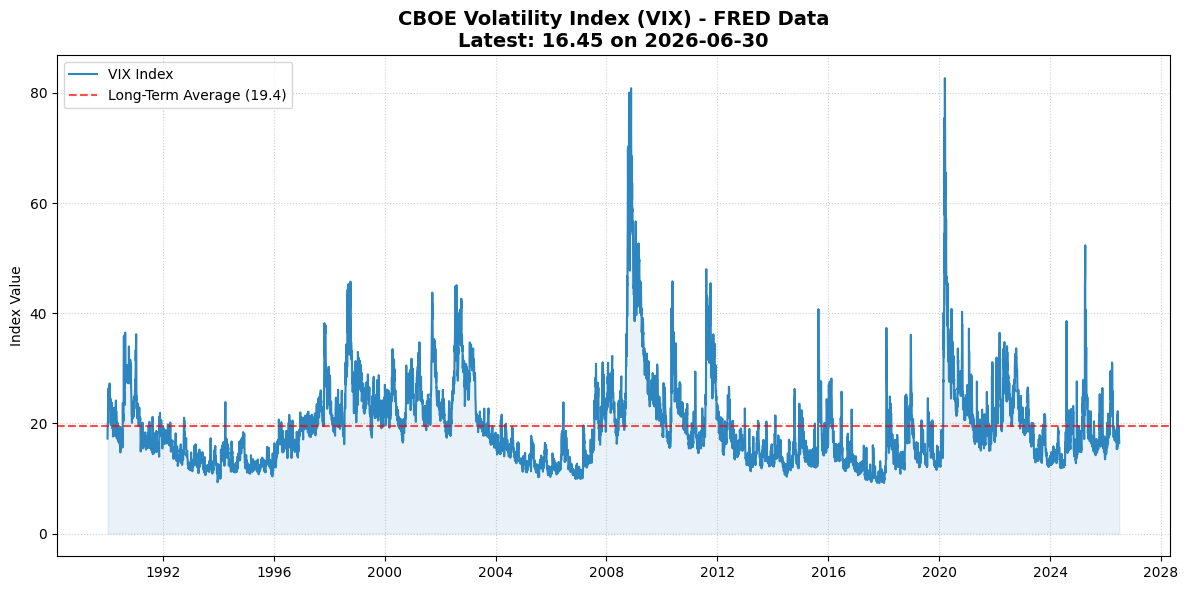

In [3]:
import pandas_datareader.data as web
import pandas as pd
import matplotlib.pyplot as plt
import datetime

def plot_vix_from_fred(end_date=datetime.datetime(2026, 6, 30)):
    # 1. Define the sample period (default end: 2026-06-30)
    start_date = datetime.datetime(1990, 1, 1)

    print(f"Fetching VIX data from FRED ({start_date.year} - {end_date.strftime('%Y-%m-%d')})...")

    try:
        # 2. Retrieve Data (Series ID: VIXCLS)
        vix_data = web.DataReader('VIXCLS', 'fred', start_date, end_date)

        # Drop NaN values (non-trading days)
        vix_data = vix_data.dropna()

        # Get the very latest value
        latest_date = vix_data.index[-1].strftime('%Y-%m-%d')
        latest_val = vix_data['VIXCLS'].iloc[-1]

        # 3. Visualization
        plt.figure(figsize=(12, 6))

        # Plot the main line
        plt.plot(vix_data.index, vix_data['VIXCLS'], color='#2E86C1', linewidth=1.5, label='VIX Index')

        # Add a horizontal line for the Long-Term Average
        long_term_avg = vix_data['VIXCLS'].mean()
        plt.axhline(long_term_avg, color='red', linestyle='--', alpha=0.7,
                    label=f'Long-Term Average ({long_term_avg:.1f})')

        # Formatting
        plt.title(f'CBOE Volatility Index (VIX) - FRED Data\nLatest: {latest_val:.2f} on {latest_date}',
                  fontsize=14, fontweight='bold')
        plt.ylabel('Index Value')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='upper left')

        # Highlight recent period
        plt.fill_between(vix_data.index, vix_data['VIXCLS'], alpha=0.1, color='#2E86C1')

        plt.tight_layout()
        plt.show()


    except Exception as e:
        print(f"Error fetching data: {e}")
        print("Ensure you have an internet connection and 'pandas_datareader' installed.")

# Run the function
plot_vix_from_fred()

### Black-Scholes Option Pricing Model
$$ C_t = S_t\times\underbrace{N(d_1)}_{\Delta_C} - \underbrace{PV(K)N(d_2)}_{\text{Borrowing}} $$
$$ P_t = \underbrace{PV(K)[1-N(d_2)]}_{\text{Lending}} + \underbrace{[N(d_1)-1]}_{\Delta_P}\times S_t $$

* Option delta, $\Delta=\partial V/\partial S$, is the local slope of the option-value curve.
  
  * For a small stock-price change: $\text{Change in option value}\approx\Delta\times\text{Change in stock price}$.
  
  * For these European options: $0<\Delta_C<1$ and $-1<\Delta_P<0$. Calls rise and puts fall when the stock price rises, holding other inputs fixed.
  
  * When the stock price changes, $\Delta$ also changes.
  
  * The stock-and-cash portfolio is tangent to the option-value curve at the current stock price. Continuous rebalancing maintains replication under the model's assumptions.

---


In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def delta_replication_values(S, K, tau, r_pct, sigma_pct, option_type):
    """Black-Scholes value, delta and cash position for non-dividend-paying stock."""
    S=np.asarray(S,dtype=float)
    if not np.all(np.isfinite(S)) or not all(math.isfinite(x) for x in (K,tau,r_pct,sigma_pct)):
        raise ValueError('All numerical inputs must be finite.')
    if np.any(S<0) or min(K,tau,sigma_pct)<=0:
        raise ValueError('Use nonnegative stock prices and positive strike, time and volatility.')
    if option_type not in {'Call','Put'}:
        raise ValueError('Choose Call or Put.')
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    gap=sigma*math.sqrt(tau)
    d1=np.full_like(S,-np.inf)
    positive=S>0
    d1[positive]=(np.log(S[positive]/K)+(r+sigma*sigma/2)*tau)/gap
    d2=d1-gap
    if option_type=='Call':
        delta=norm.cdf(d1)
        cash=-pv*norm.cdf(d2)
        price=S*delta+cash
        intrinsic=np.maximum(S-K,0)
    else:
        delta=-norm.cdf(-d1)
        cash=pv*norm.cdf(-d2)
        price=S*delta+cash
        intrinsic=np.maximum(K-S,0)
    return dict(price=np.maximum(price,0),intrinsic=intrinsic,delta=delta,cash=cash,
                pv=pv,d1=d1,d2=d2)


def plot_delta_replication(S0, K, tau, r_pct, sigma_pct, option_type):
    if not math.isfinite(S0) or S0<=0:
        raise ValueError('Use a positive current stock price.')
    x=np.linspace(0,24,801)
    curve=delta_replication_values(x,K,tau,r_pct,sigma_pct,option_type)
    m=delta_replication_values(S0,K,tau,r_pct,sigma_pct,option_type)
    value,delta,cash=(float(m[key]) for key in ('price','delta','cash'))
    d1,d2=float(m['d1']),float(m['d2'])
    tangent=delta*x+cash
    symbol='C' if option_type=='Call' else 'P'
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,(plot,calc)=plt.subplots(1,2,figsize=(16,8),gridspec_kw={'width_ratios':[1.10,1]})
    fig.subplots_adjust(left=0.065,right=0.98,top=0.80,bottom=0.18,wspace=0.19)
    fig.suptitle('Delta and the Replicating Portfolio',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
        f'European {option_type.lower()} | Stock: USD {S0:.2f} | Strike: USD {K:.2f} | '
        f'Time: {tau:g} years | Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    plot.plot(x,curve['price'],color=blue,lw=2.5,label='Option value')
    plot.plot(x,curve['intrinsic'],color=ink,ls=':',lw=1.8,label='Intrinsic value')
    plot.plot(x,tangent,color=orange,ls='--',lw=2,label='Current stock-and-cash portfolio')
    plot.scatter([S0],[value],s=65,color=orange,edgecolors=ink,zorder=6,label='Current price and value')
    plot.vlines(S0,0,value,colors='#7A8794',linestyles=':',lw=1)
    plot.hlines(value,0,S0,colors='#7A8794',linestyles=':',lw=1)
    plot.axhline(0,color=ink,lw=0.8)
    # All selected stock prices and option values fit these unchanged axes.
    plot.set(xlim=(0,24),ylim=(-10,24),xlabel='Stock price (USD)',ylabel='Value (USD)')
    plot.set_xticks(np.arange(0,25,4))
    plot.set_yticks([-10,-5,0,5,10,15,20,24])
    plot.tick_params(labelsize=13)
    plot.xaxis.label.set_size(14); plot.yaxis.label.set_size(14)
    plot.spines[['top','right']].set_visible(False)
    plot.grid(True,ls=':',alpha=0.25)
    # Place the legend away from the high-value side of the curve.
    plot.legend(loc='upper left' if option_type=='Call' else 'upper right',fontsize=11,framealpha=0.95)
    if cash < -10:
        plot.annotate('Cash intercept below view',xy=(0.4,-9.9),xytext=(1,-7),
                      fontsize=11,color=orange,arrowprops=dict(arrowstyle='->',color=orange))

    calc.set(xlim=(0,1),ylim=(0,1)); calc.axis('off')
    if option_type=='Call':
        delta_line=rf'$\Delta=N(d_1)=N({d1:.4f})={delta:.4f}$'
        cash_line=rf'$B=-PV(K)N(d_2)={cash:.4f}$'
        position=f'Buy {delta:.4f} shares; borrow USD {-cash:.4f}.'
    else:
        delta_line=rf'$\Delta=N(d_1)-1=N({d1:.4f})-1={delta:.4f}$'
        cash_line=rf'$B=PV(K)[1-N(d_2)]={cash:.4f}$'
        position=f'Short {-delta:.4f} shares; lend USD {cash:.4f}.'
    rows=[
        (0.98,'1. Delta: Slope at the selected point',16),
        (0.86,delta_line,16),
        (0.71,'2. Stock and cash positions',16),
        (0.60,cash_line,16),
        (0.49,position,14),
        (0.35,'3. Match the option value today',16),
        (0.24,rf'${symbol}_0=\Delta S_0+B={delta:.4f}({S0:.2f})+({cash:.4f})$',16),
        (0.13,rf'${symbol}_0={value:.4f}$',18),
        (0.00,rf'Tangent: $V_{{\mathrm{{rep}}}}(S)={delta:.4f}S+({cash:.4f})$',15),
    ]
    for y,text,size in rows: calc.text(0.01,y,text,fontsize=size,color=ink,va='center')
    fig.text(0.5,0.06,'The fixed portfolio matches value and slope at the selected point. Rebalance as delta changes.',
             ha='center',fontsize=15,color=ink)
    plt.show()
    return fig


def make_delta_replication_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'option_type':widgets.Dropdown(options=['Call','Put'],value='Call',description='European option:',style=style),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'S0':slider(12,0.5,20,0.5,'Stock (USD):'),
        'K':slider(13,1,20,0.5,'Strike (USD):'),
        'tau':slider(1,0.1,5,0.1,'Time (years):'),
        'sigma_pct':slider(25,5,100,1,'Annual vol. (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_delta_replication(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


delta_replication_demo=make_delta_replication_demo()
display(delta_replication_demo)


### Black-Scholes Option Pricing Model

* Risk and Return of an Option

  * The replicating portfolio has option value $V=S_t\Delta+B$, where $B$ is the cash position.
$$ \beta_{Option} = \frac{S_t \Delta}{V} \beta_S + \frac{B}{V} \beta_B $$
$$ \text{Since } \beta_B = 0, \quad \beta_{Option} = \frac{S_t \Delta}{V} \beta_S $$
$$ \Omega = \frac{S_t \Delta}{V} \quad \text{is the option's signed leverage ratio.} $$

* For a stock with positive beta: calls have positive beta; puts have negative beta.

* Delta, leverage and option beta change as the stock price changes.

---


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.special import log_ndtr
import ipywidgets as widgets
from IPython.display import display


def option_risk_values(S, K, T, r_pct, sigma_pct, option_type):
    """European, non-dividend-paying option; stable even for very small prices."""
    S = np.asarray(S, dtype=float)
    r, sigma = r_pct / 100, sigma_pct / 100
    if (not np.all(np.isfinite(S)) or np.any(S <= 0)
            or not np.all(np.isfinite([K, T, r, sigma]))
            or K <= 0 or T <= 0 or sigma <= 0):
        raise ValueError('Stock, strike, time and volatility must be positive and finite.')
    d1 = (np.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == 'Call':
        log_a = np.log(S) + log_ndtr(d1)
        log_b = np.log(K) - r * T + log_ndtr(d2)
        delta = np.exp(log_ndtr(d1))
        sign = 1
    elif option_type == 'Put':
        log_a = np.log(K) - r * T + log_ndtr(-d2)
        log_b = np.log(S) + log_ndtr(-d1)
        delta = -np.exp(log_ndtr(-d1))
        sign = -1
    else:
        raise ValueError('Choose Call or Put.')
    # Price = A - B. expm1 avoids subtracting nearly equal rounded prices.
    gap = -np.expm1(log_b - log_a)
    if np.any(gap <= 0):
        raise ArithmeticError('Option price is beyond numerical precision.')
    log_price = log_a + np.log(gap)
    leverage = 1 / gap if sign == 1 else -np.exp(log_b - log_a) / gap
    return np.exp(log_price), delta, leverage, log_price


def plot_option_risk(S0, K, T, r_pct, sigma_pct, beta_s, erm_pct, option_type):
    r, erm = r_pct / 100, erm_pct / 100
    price, delta, omega, log_price = option_risk_values(S0, K, T, r_pct, sigma_pct, option_type)
    beta_option = float(omega * beta_s)
    stock_return = r + beta_s * (erm - r)
    option_return = r + beta_option * (erm - r)
    stocks = np.linspace(50, 180, 500)
    leverage = option_risk_values(stocks, K, T, r_pct, sigma_pct, option_type)[2]
    blue, orange = '#1764a0', '#c85a12'
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    fig.subplots_adjust(left=.07, right=.97, top=.89, bottom=.38, wspace=.27)
    fig.suptitle(f'{option_type}: Leverage, Beta and Expected Return', fontsize=20)

    ax1.plot(stocks, leverage, color=blue, lw=2.5)
    ax1.axhline(0, color='0.5', lw=.8)
    ax1.axvline(S0, color=orange, ls=':', lw=1.3)
    ax1.set(xlim=(50, 180), ylim=(-15, 15))
    ax1.set_title(r'Leverage: $\Omega=S\Delta/V$', fontsize=17, pad=12)
    ax1.set_xlabel('Stock price (USD)', fontsize=14)
    ax1.set_ylabel('Signed leverage', fontsize=14)
    if -15 <= omega <= 15:
        ax1.plot(S0, omega, 'o', color=orange, ms=9)
    else:
        ax1.annotate('', xy=(S0, np.sign(omega)*14.8),
                     xytext=(S0, np.sign(omega)*11.5),
                     arrowprops=dict(arrowstyle='->', color=orange, lw=2))
    ax1.text(.03, .95, rf'Current $\Omega={omega:,.2f}$'
             + (' (outside view)' if abs(omega) > 15 else ''),
             transform=ax1.transAxes, va='top', fontsize=14,
             bbox=dict(facecolor='white', edgecolor='none', alpha=.9))

    betas = np.linspace(-10, 10, 200)
    ax2.plot(betas, r + betas*(erm-r), '--', color='0.4', lw=2, label='SML')
    ax2.axhline(0, color='0.5', lw=.8)
    ax2.axvline(0, color='0.5', lw=.8)
    ax2.plot(0, r, 'o', color='#367448', ms=7, label='Risk-free')
    ax2.plot(beta_s, stock_return, 's', color=blue, ms=8, label='Stock')
    in_view = -10 <= beta_option <= 10 and -1.1 <= option_return <= 1.1
    if in_view:
        ax2.plot(beta_option, option_return, 'o', color=orange, ms=10, label=option_type)
    else:
        # Place an arrow at the SML's intersection with the fixed view boundary.
        scale = min(9.8 / abs(beta_option),
                    1.06 / max(abs(option_return - r), 1e-12))
        edge_beta = beta_option * scale
        edge_return = r + edge_beta*(erm-r)
        if abs(edge_return) > 1.08:
            edge_return = np.copysign(1.08, edge_return)
            edge_beta = (edge_return-r)/(erm-r)
        ax2.annotate('', xy=(edge_beta, edge_return),
                     xytext=(edge_beta*.82, r + edge_beta*.82*(erm-r)),
                     arrowprops=dict(arrowstyle='->', color=orange, lw=2))
        ax2.plot([], [], 'o', color=orange, label=f'{option_type} outside view')
    ax2.set(xlim=(-10, 10), ylim=(-1.1, 1.1))
    ax2.set_title('Expected Return and Systematic Risk', fontsize=17, pad=12)
    ax2.set_xlabel(r'Beta ($\beta$)', fontsize=14)
    ax2.set_ylabel('Expected return (annualized)', fontsize=14)
    ax2.yaxis.set_major_formatter(PercentFormatter(1))
    ax2.legend(loc='upper left', fontsize=12, framealpha=.95, ncol=2)
    for ax in (ax1, ax2):
        ax.tick_params(labelsize=12)
        ax.grid(alpha=.2)

    # Scientific notation keeps small option values visible rather than rounding to zero.
    if price >= .01:
        price_text = f'{price:,.4f}'
    else:
        exponent = int(np.floor(float(log_price) / np.log(10)))
        mantissa = np.exp(float(log_price) - exponent*np.log(10))
        price_text = f'{mantissa:.3f}e{exponent:+d}'
    fig.text(.07, .27, rf'$V=${price_text} USD     $\Delta={delta:.4g}$', fontsize=16)
    fig.text(.07, .20, rf'$\Omega=S\Delta/V={omega:,.2f}$', fontsize=17, color=blue)
    fig.text(.53, .27, rf'$\beta_{{option}}=\Omega\beta_S={omega:,.2f}\times {beta_s:.2f}={beta_option:,.2f}$', fontsize=16)
    fig.text(.53, .20, rf'$\mu_{{option}}=r+\beta_{{option}}(\mu_M-r)=$ {option_return:.2%}', fontsize=16, color=orange)
    fig.text(.07, .11, 'European options on a non-dividend-paying stock. Both graph scales stay fixed.', fontsize=13)
    fig.text(.07, .06, 'CAPM returns are instantaneous rates, annualized; leverage and beta change as the stock price changes.', fontsize=13)
    plt.show()


def make_option_risk_demo():
    style = {'description_width': '125px'}
    layout = widgets.Layout(width='420px')
    controls = {'option_type': widgets.Dropdown(options=['Call', 'Put'], value='Call',
                  description='Option:', style=style, layout=layout)}
    specifications = [
        ('S0', 'Stock (USD):', 100, 50, 180, 1),
        ('K', 'Strike (USD):', 100, 50, 180, 5),
        ('T', 'Time (years):', 1, .1, 5, .1),
        ('r_pct', 'Risk-free (cc %):', 5, 0, 10, .5),
        ('sigma_pct', 'Volatility (%):', 30, 10, 100, 5),
        ('beta_s', 'Stock beta:', 1, .5, 2, .1),
        ('erm_pct', 'Market return (%):', 10, 5, 20, .5)]
    for key, label, value, low, high, step in specifications:
        controls[key] = widgets.FloatSlider(value=value, min=low, max=high, step=step,
            description=label, style=style, layout=layout, continuous_update=False)
    output = widgets.interactive_output(plot_option_risk, controls)
    grid = widgets.GridBox(list(controls.values()),
                           layout=widgets.Layout(grid_template_columns='repeat(2, 430px)'))
    return widgets.VBox([grid, output])


option_risk_demo = make_option_risk_demo()
display(option_risk_demo)


### Black-Scholes Option Pricing Model

* Lambda stock pays no dividends. Its current price is $90 and annual volatility is 30%.

* The continuously compounded risk-free rate is 6% per year. Find the value of a six-month, at-the-money European call.

$$ C_t = S_t N(d_1) - PV(K)N(d_2) $$

* Calculate $d_1$ and $d_2$, with $K=90$ and $T=0.5$:

$$ d_1 = \frac{\ln(S_t/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}}
= \frac{\ln(90/90)+(0.06+0.30^2/2)\times0.5}{0.30\sqrt{0.5}}
= \frac{0.0525}{0.30\sqrt{0.5}} \approx 0.2475 $$
$$ N(d_1) \approx 0.597734 $$

$$ d_2 = d_1-\sigma\sqrt{T} = d_1-0.30\sqrt{0.5} \approx 0.0354 $$
$$ N(d_2) \approx 0.514102 $$

* Calculate the call price:

$$ PV(K)=90e^{-0.06\times0.5}\approx87.3401 $$
$$ C_t=90N(d_1)-90e^{-0.06\times0.5}N(d_2)
\approx53.7961-44.9017=8.8944\approx\$8.89 $$

---


### Black-Scholes Option Pricing Model

Suppose the Lambda call is unavailable for trade. What portfolio should you hold today to replicate a long position in one call?

$$ C_t = \underbrace{S_t N(d_1)}_{\text{Stock Position}} + \underbrace{B}_{\text{Cash Position}},
\qquad B=-PV(K)N(d_2) $$

1. Buy $\Delta=N(d_1)\approx0.597734$ shares.
   $$ \text{Stock cost}=90N(d_1)\approx\$53.7961 $$

2. Borrow $PV(K)N(d_2)$ at the risk-free rate.
   $$ B=-90e^{-0.06\times0.5}N(d_2)\approx-\$44.9017 $$

* Net cost:
  $$ C_t=S_t\Delta+B\approx53.7961-44.9017=8.8944\approx\$8.89 $$
* Continuously rebalance the stock and cash positions as delta changes to maintain replication.

---


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import log_ndtr
import ipywidgets as widgets
from IPython.display import display


def lambda_call_values(S, K, T, r_pct, sigma_pct):
    """BSM call and signed replicating positions; no dividends."""
    r, sigma = r_pct / 100, sigma_pct / 100
    if (not np.all(np.isfinite([S, K, T, r, sigma]))
            or min(S, K, T, sigma) <= 0):
        raise ValueError('Stock, strike, time and volatility must be positive and finite.')
    log_sk = np.log(S / K)
    drift = (r + sigma**2 / 2) * T
    vol_time = sigma * np.sqrt(T)
    d1 = (log_sk + drift) / vol_time
    d2 = d1 - vol_time
    n1, n2 = norm.cdf(d1), norm.cdf(d2)
    pv_k = K * np.exp(-r * T)
    stock, cash = S * n1, -pv_k * n2
    # Stable difference for small call values, rather than cancelling rounded positions.
    log_stock = np.log(S) + log_ndtr(d1)
    log_loan = np.log(K) - r*T + log_ndtr(d2)
    gap = -np.expm1(log_loan - log_stock)
    if gap <= 0:
        raise ArithmeticError('Call value is beyond numerical precision.')
    log_call = log_stock + np.log(gap)
    return dict(d1=d1, d2=d2, n1=n1, n2=n2, pv_k=pv_k,
                stock=stock, cash=cash, call=np.exp(log_call), log_call=log_call,
                log_sk=log_sk, drift=drift, vol_time=vol_time)


def plot_lambda_call(S, K, T, r_pct, sigma_pct):
    m = lambda_call_values(S, K, T, r_pct, sigma_pct)
    blue, orange = '#1764a0', '#c85a12'
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 9))
    fig.subplots_adjust(left=.07, right=.97, top=.88, bottom=.43, wspace=.25)
    fig.suptitle('Lambda: Call Value and Replicating Portfolio', fontsize=20)
    x = np.linspace(-4, 4, 1200)
    density = norm.pdf(x)
    ax1.plot(x, density, color='0.4', lw=1.8)
    ax1.fill_between(x, density, where=x <= m['d2'], interpolate=True,
                     color=orange, alpha=.22)
    for key, color, style in [('d1', blue, '-'), ('d2', orange, '--')]:
        d, cdf = m[key], m['n'+key[-1]]
        label = rf'${key[0]}_{key[1]}={d:.4f}$; $N({key[0]}_{key[1]})={cdf:.4f}$'
        if -4 <= d <= 4:
            ax1.axvline(d, color=color, ls=style, lw=2, label=label)
        else:
            ax1.plot([], [], color=color, ls=style, lw=2, label=label+' (outside view)')
            y = .09 if key == 'd1' else .05
            ax1.annotate('', xy=(np.sign(d)*3.95, y), xytext=(np.sign(d)*3.4, y),
                         arrowprops=dict(arrowstyle='->', color=color, lw=2))
    ax1.set(xlim=(-4, 4), ylim=(0, .5))
    ax1.set_title('Standard Normal Distribution', fontsize=17, pad=12)
    ax1.set_xlabel('Standard normal value', fontsize=14)
    ax1.set_ylabel('Probability density', fontsize=14)
    ax1.legend(loc='upper left', fontsize=12, framealpha=.95)

    values = [m['stock'], m['cash'], m['call']]
    bars = ax2.bar(['Stock\n'+r'$S\Delta$', 'Cash\n'+r'$B$', 'Call\n'+r'$C=S\Delta+B$'],
                   values, color=[blue, orange, '#367448'], width=.62)
    for bar, value in zip(bars, values):
        label = f'{value:,.2f}'
        if 0 < value < .01:
            label = '<0.01'
        elif value == 0 and bar is bars[-1]:
            label = '<0.01'
        ax2.annotate(label, xy=(bar.get_x()+bar.get_width()/2, value),
                     xytext=(0, 7 if value >= 0 else -7), textcoords='offset points',
                     ha='center', va='bottom' if value >= 0 else 'top', fontsize=14)
    ax2.axhline(0, color='0.4', lw=1)
    ax2.set_ylim(-135, 135)
    ax2.set_title('Replicating Positions Today', fontsize=17, pad=12)
    ax2.set_ylabel('Value (USD)', fontsize=14)
    for ax in (ax1, ax2):
        ax.tick_params(labelsize=12)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)

    fig.text(.07, .34, 'Calculate the Call', fontsize=17, color=blue)
    fig.text(.07, .285, rf'$d_1=({m["log_sk"]:.4f}+{m["drift"]:.4f})/{m["vol_time"]:.4f}={m["d1"]:.4f}$', fontsize=16)
    fig.text(.07, .23, rf'$d_2=d_1-\sigma\sqrt{{T}}={m["d2"]:.4f}$', fontsize=16)
    fig.text(.07, .175, rf'$PV(K)={K:g}e^{{-({r_pct/100:g})({T:g})}}={m["pv_k"]:.4f}$', fontsize=16)
    if m['call'] >= .0001:
        call_text = f'{m["call"]:.4f}'
    else:
        exponent = int(np.floor(m['log_call']/np.log(10)))
        mantissa = np.exp(m['log_call']-exponent*np.log(10))
        call_text = f'{mantissa:.3f}e{exponent:+d}'
    fig.text(.54, .34, 'Replicate the Call', fontsize=17, color=orange)
    fig.text(.54, .285, rf'Buy $\Delta=N(d_1)={m["n1"]:.6f}$ shares', fontsize=16)
    fig.text(.54, .23, rf'$B=-PV(K)N(d_2)={m["cash"]:.4f}$ USD', fontsize=16)
    fig.text(.54, .175, rf'$C=S\Delta+B=$ {call_text} USD', fontsize=16)
    fig.text(.07, .09, r'$N(d_2)$: risk-neutral probability of finishing in the money. $N(d_1)$: call delta.', fontsize=13)
    fig.text(.07, .045, 'Rebalance as delta changes. Calculations use full precision; displayed intermediate values are rounded.', fontsize=13)
    plt.show()


def make_lambda_call_demo():
    style = {'description_width': '125px'}
    specifications = [
        ('S', 'Stock (USD):', 90, 40, 120, 1),
        ('K', 'Strike (USD):', 90, 40, 120, 1),
        ('T', 'Time (years):', .5, .1, 2, .1),
        ('r_pct', 'Risk-free (cc %):', 6, 0, 10, .5),
        ('sigma_pct', 'Volatility (%):', 30, 5, 100, 5)]
    controls = {key: widgets.FloatSlider(value=value, min=low, max=high, step=step,
                    description=label, style=style, layout=widgets.Layout(width='420px'),
                    continuous_update=False)
                for key, label, value, low, high, step in specifications}
    output = widgets.interactive_output(plot_lambda_call, controls)
    grid = widgets.GridBox(list(controls.values()),
                           layout=widgets.Layout(grid_template_columns='repeat(2, 430px)'))
    return widgets.VBox([grid, output])


lambda_call_demo = make_lambda_call_demo()
display(lambda_call_demo)


### Black-Scholes Option Pricing Model

* Theta is considering a European call on Sigma stock, which pays no dividends. The stock price is $120, the strike is $125, and the option expires in nine months.

* Annual volatility is 28%, and the continuously compounded risk-free rate is 4% per year.

* Using the Black-Scholes formula, compute the call price.

$$ d_1=\frac{\ln(120/125)+(0.04+0.5(0.28)^2)\times0.75}{0.28\sqrt{0.75}} $$
$$ d_1\approx\frac{-0.040822+0.059400}{0.242487}\approx0.0766,
\qquad N(d_1)\approx0.530535 $$

$$ d_2=d_1-0.28\sqrt{0.75}\approx-0.1659,
\qquad N(d_2)\approx0.434129 $$

$$ C_t=S_tN(d_1)-Ke^{-rT}N(d_2) $$
$$ C_t=120N(d_1)-125e^{-0.04\times0.75}N(d_2) $$
$$ C_t\approx63.6642-52.6623=11.0019\approx\$11.00 $$

* Use put-call parity to compute the price of the European put with the same strike and expiration date.

$$ P_t=C_t-S_t+Ke^{-rT} $$
$$ P_t=C_t-120+125e^{-0.04\times0.75} $$
$$ P_t\approx11.0019-120+121.3057=12.3076\approx\$12.31 $$

---


### Stock Valuation: Kappa

* Kappa has assets worth USD 150 million, with annual asset volatility of 25%.

* Financing: 6 million ordinary shares and one zero-coupon debt issue; USD 120 million is due in two years.

* The risk-free rate is 4% per year, continuously compounded.

* Assume the Black-Scholes framework applies to the firm's assets. No payouts before maturity, no other claims or bankruptcy costs; default can occur only at maturity.

a. Use a two-period binomial tree with one-year steps, $u=e^{\sigma_V\sqrt{\Delta t}}$ and $d=1/u$, to determine the market value of equity, the value per share and the market value of debt.

b. Repeat the valuation using Black-Scholes and compare the results.

c. A proposed change in operations would reduce current asset value to USD 147 million and increase asset volatility to 40%. Debt terms and the number of shares remain unchanged; no new financing is required. Use Black-Scholes to revalue the shares and debt. Assess the proposal from the shareholders' and lenders' perspectives.

---



### Stock Valuation: Kappa

* Two one-year steps: $\Delta t=1$. All firm values are in USD millions.
  $$ u=e^{0.25\sqrt{1}}=1.284025,\qquad d=1/u=0.778801 $$
* Risk-neutral up probability:
  $$ p=\frac{e^{r_f\Delta t}-d}{u-d}
  =\frac{e^{0.04}-0.778801}{1.284025-0.778801}=0.518601 $$
* Asset values after one year:
  $$ V_u=150u=192.6038,\qquad V_d=150d=116.8201 $$
* At maturity, lenders have priority; shareholders receive the remainder, with limited liability:
  $$ E_T=\max(V_T-120,0),\qquad D_T=\min(V_T,120). $$

| State at year 2 | Assets, $V_T$ | Equity, $E_T$ | Debt, $D_T$ |
|:--|--:|--:|--:|
| Up-up: $150u^2$ | 247.3082 | 127.3082 | 120.0000 |
| Up-down: $150ud$ | 150.0000 | 30.0000 | 120.0000 |
| Down-down: $150d^2$ | 90.9796 | 0.0000 | 90.9796 |

---



### Stock Valuation: Kappa

* Work backward using risk-neutral probabilities and the risk-free rate:
  $$ E_u=e^{-0.04}[p(127.3082)+(1-p)(30)]=77.3091 $$
  $$ E_d=e^{-0.04}[p(30)+(1-p)(0)]=14.9480 $$
  $$ E_0=e^{-0.04}[pE_u+(1-p)E_d]=45.4343 $$

$$ \text{Value per share}=\frac{45.4343}{6}=\$7.57 $$

* Equity and debt together own all firm assets:
  $$ D_0=V_0-E_0=150-45.4343=104.5657 $$

* Check by discounting the debt payoffs directly:
  $$ D_0=e^{-0.04\times2}
  [p^2(120)+2p(1-p)(120)+(1-p)^2(90.9796)]
  =104.5657 $$

---



In [9]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display


def kappa_binomial_values():
    """Kappa example: two annual CRR steps, continuous risk-free rate."""
    V0, F, sigma, rate, dt = 150, 120, 0.25, 0.04, 1
    u = math.exp(sigma * math.sqrt(dt))
    d = 1 / u
    r = math.exp(rate * dt)
    if not d < r < u:
        raise ValueError("No-arbitrage requires d < exp(r_f dt) < u.")
    p = (r - d) / (u - d)
    assets = {"0": V0, "u": V0*u, "d": V0*d,
              "uu": V0*u*u, "ud": V0*u*d, "dd": V0*d*d}
    claims = {}
    for name in ("Equity", "Debt"):
        values = {node: (max(assets[node]-F, 0) if name == "Equity"
                         else min(assets[node], F))
                  for node in ("uu", "ud", "dd")}
        values["u"] = (p*values["uu"] + (1-p)*values["ud"]) / r
        values["d"] = (p*values["ud"] + (1-p)*values["dd"]) / r
        values["0"] = (p*values["u"] + (1-p)*values["d"]) / r
        claims[name] = values
    return dict(assets=assets, claims=claims, u=u, d=d, r=r, p=p)


def plot_kappa_binomial(step=4, claim="Equity"):
    m = kappa_binomial_values()
    values = m["claims"][claim]
    symbol = "E" if claim == "Equity" else "D"
    p, q, r = m["p"], 1-m["p"], m["r"]
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    neutral, pale = "#526172", "#F2F4F7"
    fig, (tree, calc) = plt.subplots(
        1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.40, 1]})
    fig.subplots_adjust(left=0.02, right=0.98, top=0.79, bottom=0.17, wspace=0.12)
    fig.suptitle("Kappa: Two-Period Binomial Stock Valuation",
                 fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.90,
             "Two 1-year periods | Debt face value: USD 120m | "
             "Asset volatility: 25% | Risk-free rate: 4% (continuous)",
             ha="center", fontsize=14, color=ink)
    for ax in (tree, calc):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")
    positions = {"0": (0.13, 0.50), "u": (0.49, 0.665), "d": (0.49, 0.335),
                 "uu": (0.85, 0.83), "ud": (0.85, 0.50), "dd": (0.85, 0.17)}
    for x, label in [(0.13, "Today"), (0.49, "Year 1"), (0.85, "Year 2")]:
        tree.text(x, 0.985, label, ha="center", fontsize=15, color=ink)
    for start, end, up in [("0", "u", True), ("0", "d", False),
                           ("u", "uu", True), ("u", "ud", False),
                           ("d", "ud", True), ("d", "dd", False)]:
        x1, y1 = positions[start]
        x2, y2 = positions[end]
        color = blue if up else orange
        left, right = (x1+0.13, y1), (x2-0.13, y2)
        backward = (step >= 3 and start in ("u", "d")) or (
                    step == 4 and start == "0")
        tree.annotate("", xy=left if backward else right,
                      xytext=right if backward else left,
                      arrowprops=dict(arrowstyle="-|>", color=color, lw=2,
                                      mutation_scale=16))
        label = ("$u$" if up else "$d$") if step == 1 else (
                 "$p$" if up else "$1-p$")
        tree.text((x1+x2)/2, (y1+y2)/2+(0.045 if up else -0.045),
                  label, ha="center", va="center", fontsize=14, color=color)
    for node, (x, y) in positions.items():
        color, fill = ((blue, "#EEF5FB") if node in ("u", "uu") else
                       (orange, "#FFF4E9") if node in ("d", "dd") else
                       (neutral, pale))
        tree.add_patch(FancyBboxPatch(
            (x-0.115, y-0.105), 0.23, 0.21,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            facecolor=fill, edgecolor=color, linewidth=1.8, zorder=2))
        tree.text(x, y+0.04, f"Assets: {m['assets'][node]:.2f}",
                  ha="center", fontsize=15, color=ink)
        visible = (len(node) == 2 and step >= 2) or (
                   node in ("u", "d") and step >= 3) or (node == "0" and step == 4)
        text = ("$" + rf"{symbol}_{{{node}}}={values[node]:.4f}$" if visible
                else (claim + ": ?") if step >= 2 else "")
        tree.text(x, y-0.045, text, ha="center", fontsize=16, color=color)

    def row(y, text, size=16):
        calc.text(0.01, y, text, fontsize=size, color=ink, va="center")

    if step == 1:
        row(0.97, "1. Build the asset tree")
        row(0.82, rf"$u=e^{{0.25\sqrt{{1}}}}={m['u']:.6f}$")
        row(0.67, rf"$d=1/u={m['d']:.6f}$")
        row(0.52, r"$V_u=150u,\quad V_d=150d$")
        row(0.37, r"$V_{uu}=150u^2,\quad V_{ud}=150ud$")
        row(0.22, r"$V_{dd}=150d^2$")
        row(0.07, "No payouts before debt maturity.", 15)
    elif step == 2:
        row(0.97, "2. Apply the terminal payoffs")
        payoff = r"\max(V_T-120,0)" if claim == "Equity" else r"\min(V_T,120)"
        row(0.82, "$" + rf"{symbol}_T={payoff}$")
        for y, node in [(0.63, "uu"), (0.44, "ud"), (0.25, "dd")]:
            expr = (rf"\max({m['assets'][node]:.4f}-120,0)" if claim == "Equity"
                    else rf"\min({m['assets'][node]:.4f},120)")
            row(y, "$" + rf"{symbol}_{{{node}}}={expr}$", 15)
            row(y-0.075, rf"$={values[node]:.4f}$", 16)
        row(0.04, r"$E_T+D_T=V_T$ in every state.", 15)
    else:
        row(0.98, "3. Work backward: Year 2 to Year 1")
        row(0.87, rf"$r=e^{{0.04}}={r:.6f}$", 15)
        row(0.74, rf"$p=\frac{{r-d}}{{u-d}}={p:.6f},\quad 1-p={q:.6f}$", 15)
        for y, node, up, down in [(0.57, "u", "uu", "ud"), (0.40, "d", "ud", "dd")]:
            row(y, "$" + rf"{symbol}_{{{node}}}="
                   rf"\frac{{{p:.4f}({values[up]:.4f})+{q:.4f}({values[down]:.4f})}}"
                   rf"{{{r:.6f}}}\approx {values[node]:.4f}$", 15)
        if step == 4:
            row(0.23, "4. Work backward: Year 1 to Today")
            row(0.06, "$" + rf"{symbol}_0="
                      rf"\frac{{{p:.4f}({values['u']:.4f})+{q:.4f}({values['d']:.4f})}}"
                      rf"{{{r:.6f}}}\approx {values['0']:.4f}$", 15)
    if step == 4:
        equity, debt = m["claims"]["Equity"]["0"], m["claims"]["Debt"]["0"]
        fig.text(0.5, 0.085,
                 rf"$E_0={equity:.4f},\quad D_0={debt:.4f},\quad E_0+D_0=150"
                 rf"\qquad \mathrm{{Stock\ value}}=\frac{{{equity:.4f}}}{{6}}"
                 rf"=\mathrm{{USD}}\ {equity/6:.2f}$",
                 ha="center", fontsize=17, color=ink)
    fig.text(0.5, 0.025, "Firm values in USD millions; stock value in USD per share.",
             ha="center", fontsize=14, color=ink)
    plt.show()
    return fig


def make_kappa_binomial_demo():
    step = widgets.SelectionSlider(
        options=[("1. Assets", 1), ("2. Payoffs", 2),
                 ("3. Year 1", 3), ("4. Today", 4)], value=4,
        description="Step:", continuous_update=False,
        style={"description_width": "60px"}, layout=widgets.Layout(width="540px"))
    claim = widgets.Dropdown(options=["Equity", "Debt"], value="Equity",
                             description="Claim:", layout=widgets.Layout(width="260px"))
    def render(step, claim):
        plot_kappa_binomial(step, claim)
    output = widgets.interactive_output(render, {"step": step, "claim": claim})
    return widgets.VBox([widgets.HBox([step, claim]), output])


kappa_binomial_demo = make_kappa_binomial_demo()
display(kappa_binomial_demo)


### Stock Valuation: Kappa

* Equity is a European call on firm assets: $S_0=V_0=150$, $K=F=120$, $T=2$, $\sigma=\sigma_V=0.25$.
* Use asset volatility, not stock volatility. All firm values below are in USD millions.

$$ PV(F)=120e^{-0.04\times2}=110.7740 $$

$$ d_1=\frac{\ln(150/120)+(0.04+0.25^2/2)\times2}{0.25\sqrt{2}}
=1.0342,\qquad d_2=d_1-0.25\sqrt{2}=0.6806 $$

$$ N(d_1)=0.849478,\qquad N(d_2)=0.751951 $$

$$ E_0=V_0N(d_1)-Fe^{-r_fT}N(d_2)
=127.4217-83.2966=44.1250 $$

$$ \text{Value per share}=\frac{44.1250}{6}=\$7.35,\qquad
D_0=V_0-E_0=150-44.1250=105.8750 $$

* The two-period tree gives USD 7.57 per share; Black-Scholes gives USD 7.35. Two steps are a coarse approximation; the binomial model converges to Black-Scholes as the number of steps increases.

---



### Stock Valuation: Kappa

* Under the proposal, $V_0=147$ and $\sigma_V=0.40$; $PV(F)$ remains 110.7740.

$$ d_1=\frac{\ln(147/120)+(0.04+0.40^2/2)\times2}{0.40\sqrt{2}}
=0.7830,\qquad d_2=d_1-0.40\sqrt{2}=0.2173 $$

$$ N(d_1)=0.783191,\qquad N(d_2)=0.586025 $$

$$ E_0=147N(d_1)-120e^{-0.04\times2}N(d_2)
=115.1291-64.9163=50.2128 $$

$$ \text{Value per share}=\frac{50.2128}{6}=\$8.37,\qquad
D_0=147-50.2128=96.7872 $$

| Value | Current operations | Proposal | Change |
|:--|--:|--:|--:|
| Assets (USD m) | 150.0000 | 147.0000 | -3.0000 |
| Equity (USD m) | 44.1250 | 50.2128 | +6.0878 |
| Debt (USD m) | 105.8750 | 96.7872 | -9.0878 |

* Shareholders gain despite the USD 3 million loss in total asset value: higher volatility raises the value of their limited-liability claim enough to offset the asset-value loss.
* Lenders lose USD 9.0878 million. With debt terms unchanged, shareholders favor the proposal and lenders oppose it; a higher stock value does not imply value creation for the firm.

---



In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr
import ipywidgets as widgets
from IPython.display import display


def kappa_volatility_values(asset_value, sigma_pct):
    """Black-Scholes capital structure; firm values in USD millions."""
    V = np.asarray(asset_value, dtype=float)
    sigma = np.asarray(sigma_pct, dtype=float) / 100
    if np.any(~np.isfinite(V)) or np.any(V <= 0):
        raise ValueError("Asset value must be positive and finite.")
    if np.any(~np.isfinite(sigma)) or np.any(sigma <= 0):
        raise ValueError("Asset volatility must be positive and finite.")
    F, T, r_f = 120.0, 2.0, 0.04
    d1 = (np.log(V/F) + (r_f + sigma**2/2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    equity = V*ndtr(d1) - F*np.exp(-r_f*T)*ndtr(d2)
    return equity, V-equity


def plot_kappa_volatility(asset_value=147, sigma_pct=40):
    ink, blue, orange, neutral = "#172333", "#005A9C", "#A64B00", "#526172"
    base = np.array(kappa_volatility_values(150, 25), dtype=float)
    intermediate = np.array(kappa_volatility_values(asset_value, 25), dtype=float)
    selected = np.array(kappa_volatility_values(asset_value, sigma_pct), dtype=float)
    asset_effect = intermediate-base
    volatility_effect = selected-intermediate
    total = selected-base
    grid = np.linspace(80, 200, 501)
    base_curves = kappa_volatility_values(grid, 25)
    curves = kappa_volatility_values(grid, sigma_pct)
    fig, axes = plt.subplots(2, 2, figsize=(17, 11),
                             gridspec_kw={"height_ratios": [1.2, 0.85]})
    fig.subplots_adjust(left=0.065, right=0.97, top=0.85, bottom=0.10,
                        hspace=0.47, wspace=0.25)
    fig.suptitle("Kappa: Asset Value, Volatility and the Division of Value",
                 fontsize=20, color=ink, y=0.98)
    fig.text(0.5, 0.935,
             f"Reference: assets USD 150m, volatility 25%    |    "
             f"Selected: assets USD {asset_value:g}m, volatility {sigma_pct:g}%",
             ha="center", fontsize=15, color=ink)
    fig.text(0.5, 0.895,
             "Debt face value: USD 120m | Maturity: 2 years | Risk-free rate: 4% (continuous)",
             ha="center", fontsize=14, color=ink)
    for j, (name, color) in enumerate([("Equity", blue), ("Debt", orange)]):
        ax = axes[0, j]
        ax.plot(grid, base_curves[j], color=neutral, lw=2, ls="--",
                label="Volatility: 25%")
        ax.plot(grid, curves[j], color=color, lw=2.7,
                label=f"Volatility: {sigma_pct:g}%")
        ax.fill_between(grid, base_curves[j], curves[j], color=color, alpha=0.12)
        ax.axvline(asset_value, color=neutral, ls=":", lw=1.2)
        ax.scatter([150], [base[j]], s=100, facecolors="white", edgecolors=ink,
                   linewidths=1.8, zorder=5, label="Reference position")
        ax.scatter([asset_value], [selected[j]], s=110, color=color,
                   edgecolors="white", linewidths=1.2, zorder=6,
                   label="Selected position", clip_on=False)
        if abs(selected[j]-intermediate[j]) > 0.05:
            ax.annotate("", xy=(asset_value, selected[j]),
                        xytext=(asset_value, intermediate[j]),
                        arrowprops=dict(arrowstyle="-|>", lw=2, color=color,
                                        mutation_scale=16))
        ax.set(xlim=(80, 200), ylim=(0, 125))
        ax.set_xticks(np.arange(80, 201, 20))
        ax.set_yticks(np.arange(0, 126, 25))
        ax.set_title(f"{name}: USD {selected[j]:.4f}m", fontsize=18, color=color, pad=10)
        ax.set_xlabel("Current asset value (USD millions)", fontsize=14)
        ax.set_ylabel(f"{name} value (USD millions)", fontsize=14)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left", fontsize=11, ncol=2, framealpha=0.92)

    changes = axes[1, 0]
    x = np.arange(3)
    for j, (name, color, offset) in enumerate(
            [("Equity", blue, -0.18), ("Debt", orange, 0.18)]):
        values = [asset_effect[j], volatility_effect[j], total[j]]
        bars = changes.bar(x+offset, values, width=0.32, color=color, label=name)
        for bar, value in zip(bars, values):
            changes.annotate(f"{value:+.2f}",
                (bar.get_x()+bar.get_width()/2, value),
                xytext=(0, 5 if value >= 0 else -5), textcoords="offset points",
                ha="center", va="bottom" if value >= 0 else "top",
                fontsize=12, color=color)
    changes.axhline(0, color=ink, lw=1)
    changes.set_ylim(-80, 80)
    changes.set_yticks([-80, -40, 0, 40, 80])
    changes.set_xticks(x, ["1. Asset value\nat 25% volatility",
                          "2. Volatility\nat selected asset value", "Total change"])
    changes.tick_params(labelsize=12)
    changes.set_ylabel("Change in value (USD millions)", fontsize=13)
    changes.set_title("Separate the Two Effects", fontsize=17, color=ink)
    changes.grid(axis="y", alpha=0.2)
    changes.legend(loc="upper left", ncol=2, fontsize=12)

    calc = axes[1, 1]
    calc.axis("off")
    calc.set_title("Reference and Selected Values", fontsize=17, color=ink)
    table = calc.table(
        cellText=[
            ["Assets", "150.0000", f"{asset_value:.4f}", f"{asset_value-150:+.4f}"],
            ["Equity", f"{base[0]:.4f}", f"{selected[0]:.4f}", f"{total[0]:+.4f}"],
            ["Debt", f"{base[1]:.4f}", f"{selected[1]:.4f}", f"{total[1]:+.4f}"],
            ["Stock (USD)", f"{base[0]/6:.2f}", f"{selected[0]/6:.2f}",
             f"{total[0]/6:+.2f}"]],
        colLabels=["USD m", "Reference", "Selected", "Change"],
        colWidths=[0.25, 0.25, 0.25, 0.25], cellLoc="center", bbox=[0, 0.23, 1, 0.71])
    table.auto_set_font_size(False)
    table.set_fontsize(13)
    for (row, col), cell in table.get_celld().items():
        color = blue if row in (2, 4) else orange if row == 3 else ink
        fill = "#EEF5FB" if row in (2, 4) else "#FFF4E9" if row == 3 else "#F2F4F7"
        cell.set_edgecolor("#D2D8E0")
        cell.set_facecolor(fill)
        cell.get_text().set_color(color)
    calc.text(0.5, 0.06,
              rf"$\Delta E+\Delta D={total[0]:+.4f}+({total[1]:+.4f})"
              rf"={asset_value-150:+.4f}=\Delta V$",
              ha="center", transform=calc.transAxes, fontsize=16, color=ink)
    fig.text(0.5, 0.035,
             "Curve shading isolates the volatility effect. "
             "The bars change asset value first, then volatility.",
             ha="center", fontsize=14, color=ink)
    plt.show()
    return fig


def make_kappa_volatility_demo():
    style = {"description_width": "150px"}
    asset = widgets.FloatSlider(value=147, min=80, max=200, step=1,
        description="Asset value (USD m):", readout_format=".0f",
        continuous_update=False, style=style, layout=widgets.Layout(width="480px"))
    volatility = widgets.FloatSlider(value=40, min=5, max=80, step=1,
        description="Asset volatility (%):", readout_format=".0f",
        continuous_update=False, style=style, layout=widgets.Layout(width="480px"))
    def render(asset_value, sigma_pct):
        plot_kappa_volatility(asset_value, sigma_pct)
    output = widgets.interactive_output(render, {"asset_value": asset, "sigma_pct": volatility})
    return widgets.VBox([widgets.HBox([asset, volatility]), output])


kappa_volatility_demo = make_kappa_volatility_demo()
display(kappa_volatility_demo)


### Binomial Option Pricing Model: Two-Year Call

* Delta stock pays no dividends and trades at $S_0=\$80$. It rises or falls by 25% each year.
* Value a two-year European call with $K=\$84$, then the corresponding American call.
* Two one-year periods; annual effective risk-free rate: 5%.

$$ u=1.25,\qquad d=0.75,\qquad r=1.05 $$

$$ p=\frac{r-d}{u-d}=\frac{1.05-0.75}{1.25-0.75}=0.60,
\qquad 1-p=0.40 $$

$$ S_0=80\longrightarrow
\begin{cases}
S_u=100\longrightarrow\begin{cases}S_{uu}=125\\S_{ud}=75\end{cases}\\
S_d=60\longrightarrow\begin{cases}S_{du}=75\\S_{dd}=45\end{cases}
\end{cases} $$

---



### Binomial Option Pricing Model: Two-Year Call

* Year 2: Calculate the European call payoffs.
  $$ C_{uu}=\max(125-84,0)=41 $$
  $$ C_{ud}=C_{du}=\max(75-84,0)=0,\qquad C_{dd}=\max(45-84,0)=0 $$

* Year 1: Discount the two possible payoffs from each node.
  $$ C_u^E=\frac{pC_{uu}+(1-p)C_{ud}}{r}
  =\frac{0.60(41)+0.40(0)}{1.05}\approx23.4286 $$
  $$ C_d^E=\frac{pC_{du}+(1-p)C_{dd}}{r}
  =\frac{0.60(0)+0.40(0)}{1.05}=0 $$

* Year 0: Discount the year-1 option values.
  $$ C_0^E=\frac{pC_u^E+(1-p)C_d^E}{r}
  \approx\frac{0.60(23.4286)+0.40(0)}{1.05}
  =13.3878\approx\$13.39 $$

---



### Binomial Option Pricing Model: Two-Year Call

* Year 2: The American call has the same terminal payoffs.
  $$ C_{uu}=\max(125-84,0)=41 $$
  $$ C_{ud}=C_{du}=\max(75-84,0)=0,\qquad C_{dd}=\max(45-84,0)=0 $$

* Year 1, up node: Calculate continuation, then compare with exercise.
  $$ H_u=\frac{0.60(41)+0.40(0)}{1.05}\approx23.4286 $$
  $$ I_u=\max(100-84,0)=16,\qquad
  C_u^A=\max(I_u,H_u)\approx\max(16,23.4286)=23.4286\quad\text{(Hold)} $$

* Year 1, down node:
  $$ H_d=\frac{0.60(0)+0.40(0)}{1.05}=0 $$
  $$ I_d=\max(60-84,0)=0,\qquad C_d^A=\max(I_d,H_d)=\max(0,0)=0 $$

---



### Binomial Option Pricing Model: Two-Year Call

* Year 0: Use the American values already determined at year 1.
  $$ H_0=\frac{pC_u^A+(1-p)C_d^A}{r}
  \approx\frac{0.60(23.4286)+0.40(0)}{1.05}
  =13.3878 $$

* Compare continuation with exercise today:
  $$ I_0=\max(80-84,0)=0 $$
  $$ C_0^A=\max(I_0,H_0)\approx\max(0,13.3878)=13.3878\quad\text{(Hold)} $$

$$ C_0^A=C_0^E\approx\$13.39,\qquad
\text{Early-exercise premium}=0 $$

* With no dividends and a positive interest rate, early exercise provides no advantage for this call.

---



In [17]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def two_period_call_comparison_values(S0, K, u_pct, d_pct, r_pct, option_style):
    """European and American calls, two annual periods, no dividends."""
    if not all(math.isfinite(x) for x in (S0,K,u_pct,d_pct,r_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price and strike, and a rate above -100%.")
    if option_style not in {"European","American"}:
        raise ValueError("Choose European or American.")
    u,d,r=1+u_pct/100,1+d_pct/100,1+r_pct/100
    if not 0 < d < r < u:
        raise ValueError(
            f"No-arbitrage requires 0 < d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves or rate; no option price is shown.")
    p=(r-d)/(u-d); q=1-p
    stocks={'0':S0,'u':S0*u,'d':S0*d,'uu':S0*u*u,'ud':S0*u*d,'dd':S0*d*d}
    terminal={key:max(stocks[key]-K,0) for key in ('uu','ud','dd')}
    nodes={}
    def value_node(key, euro_up, euro_down, amer_up, amer_down):
        intrinsic=max(stocks[key]-K,0)
        european=(p*euro_up+q*euro_down)/r
        hold_american=(p*amer_up+q*amer_down)/r
        american=max(intrinsic,hold_american)
        if intrinsic == 0 and hold_american == 0:
            decision='Worthless'
        elif math.isclose(intrinsic,hold_american,rel_tol=1e-10,abs_tol=1e-10):
            decision='Indifferent'
        else:
            decision='Exercise now' if intrinsic>hold_american else 'Hold'
        return dict(I=intrinsic,E=european,A=american,
                    H=hold_american if option_style=='American' else european,
                    P=american if option_style=='American' else european,
                    decision=decision if option_style=='American' else 'European')
    for key,high,low in [('u','uu','ud'),('d','ud','dd')]:
        nodes[key]=value_node(key,terminal[high],terminal[low],terminal[high],terminal[low])
    nodes['0']=value_node('0',nodes['u']['E'],nodes['d']['E'],nodes['u']['A'],nodes['d']['A'])
    return dict(u=u,d=d,r=r,p=p,q=q,stocks=stocks,terminal=terminal,nodes=nodes,
                european=nodes['0']['E'],american=nodes['0']['A'])


def plot_two_period_call_comparison(S0, K, u_pct, d_pct, r_pct, option_style):
    m=two_period_call_comparison_values(S0,K,u_pct,d_pct,r_pct,option_style)
    ink,blue,orange='#172333','#005A9C','#A64B00'
    red,neutral='#9B1C31','#526172'
    fig,(tree,calc)=plt.subplots(1,2,figsize=(17,10),gridspec_kw={'width_ratios':[1.40,1]})
    fig.subplots_adjust(left=0.02,right=0.98,top=0.69,bottom=0.15,wspace=0.12)
    fig.suptitle('Two-Period European and American Calls',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.91,
             f'{option_style} call | Strike: USD {K:.2f} | Two one-year periods | '
             f'Annual effective rate: {r_pct:g}%',ha='center',fontsize=14,color=ink)
    fig.text(0.5,0.845,
             rf"$u={m['u']:.2f},\quad d={m['d']:.2f},\quad r={m['r']:.4f},\quad "
             rf"p=\frac{{r-d}}{{u-d}}={m['p']:.4f},\quad 1-p={m['q']:.4f}$",
             ha='center',fontsize=16,color=ink)
    fig.text(0.5, 0.785, '1. Year 2: Start with the terminal payoffs',
             ha='center', fontsize=16, color=ink)
    fig.text(0.5, 0.74,
             rf"$C_{{uu}}=\max({m['stocks']['uu']:.2f}-{K:.2f},0)={m['terminal']['uu']:.2f}"
             rf"\quad C_{{ud}}=C_{{du}}=\max({m['stocks']['ud']:.2f}-{K:.2f},0)={m['terminal']['ud']:.2f}"
             rf"\quad C_{{dd}}=\max({m['stocks']['dd']:.2f}-{K:.2f},0)={m['terminal']['dd']:.2f}$",
             ha='center', fontsize=15, color=ink)
    for ax in (tree,calc):
        ax.set(xlim=(0,1),ylim=(0,1)); ax.axis('off')
    for x,label in [(0.13,'Today'),(0.49,'Year 1'),(0.85,'Year 2')]:
        tree.text(x,0.985,label,ha='center',fontsize=15,color=ink)
    positions={'0':(0.13,0.50),'u':(0.49,0.665),'d':(0.49,0.335),
               'uu':(0.85,0.83),'ud':(0.85,0.50),'dd':(0.85,0.17)}
    dashed=False
    for start,end,is_up in [('0','u',True),('0','d',False),('u','uu',True),
                            ('u','ud',False),('d','ud',True),('d','dd',False)]:
        x1,y1=positions[start]; x2,y2=positions[end]
        hypothetical=(m['nodes']['0']['decision']=='Exercise now' or
                      m['nodes'][start]['decision']=='Exercise now')
        dashed |= hypothetical
        color=blue if is_up else orange
        tree.annotate('',xy=(x1+0.13,y1),xytext=(x2-0.13,y2),arrowprops=dict(
            arrowstyle='-|>',color=color,lw=2,mutation_scale=16,
            linestyle='--' if hypothetical else '-',alpha=0.45 if hypothetical else 1))
        tree.text((x1+x2)/2,(y1+y2)/2+(0.045 if is_up else -0.085),
                  '$p$' if is_up else '$1-p$',ha='center',va='center',fontsize=14,color=color)
    for name,(x,y) in positions.items():
        is_terminal=len(name)==2
        if is_terminal:
            color,fill=neutral,'#F2F4F7'
        else:
            exercise=m['nodes'][name]['decision']=='Exercise now'
            color,fill=(red,'#FFF0F2') if exercise else (blue,'#EEF5FB')
        height=0.21 if is_terminal else 0.25
        tree.add_patch(FancyBboxPatch((x-0.115,y-height/2),0.23,height,
            boxstyle='round,pad=0.012,rounding_size=0.018',facecolor=fill,
            edgecolor=color,linewidth=1.8,zorder=2))
        tree.text(x,y+(0.04 if is_terminal else 0.065),f"Stock: {m['stocks'][name]:.2f}",
                  ha='center',fontsize=15,color=ink)
        if is_terminal:
            tree.text(x,y-0.045,f"Payoff: {m['terminal'][name]:.2f}",ha='center',fontsize=16,color=ink)
        else:
            node=m['nodes'][name]
            tree.text(x,y-0.005,rf"$C_{{{name}}}={node['P']:.4f}$",ha='center',fontsize=16,color=color)
            tree.text(x,y-0.08,node['decision'],ha='center',fontsize=14,color=color)

    # At the root, American continuation uses the already optimized year-1 values.
    p,q,r=m['p'],m['q'],m['r']
    for key,title,top,high,low in [
        ('u','2. Year 1: Up node',0.98,m['terminal']['uu'],m['terminal']['ud']),
        ('d','2. Year 1: Down node',0.63,m['terminal']['ud'],m['terminal']['dd']),
        ('0','3. Year 0: Today',0.28,m['nodes']['u']['P'],m['nodes']['d']['P'])]:
        node=m['nodes'][key]
        calc.text(0.01,top,title,fontsize=16,color=ink,va='center')
        calc.text(0.01,top-0.11,
                  rf"$H_{{{key}}}=\frac{{{p:.4f}({high:.4f})+{q:.4f}({low:.4f})}}{{{r:.4f}}}\approx {node['H']:.4f}$",
                  fontsize=16,color=ink,va='center')
        if option_style=='American':
            line=(rf"$C_{{{key}}}=\max({node['I']:.4f},{node['H']:.4f})"
                  rf"\approx {node['P']:.4f}$")
        else:
            line=rf"$C_{{{key}}}=H_{{{key}}}\approx {node['P']:.4f}$"
        calc.text(0.01,top-0.21,line,fontsize=16,
                  color=red if node['decision']=='Exercise now' else blue,va='center')
    fig.text(0.5,0.105,
             rf"$H$: Continuation value; American call: $C=\max(\max(S-K,0),H)$.",
             ha='center',fontsize=16,color=ink)
    fig.text(0.5,0.06,
             f"European today: {m['european']:.4f} | American today: {m['american']:.4f} | "
             f"Early-exercise premium: {m['american']-m['european']:.4f}",
             ha='center',fontsize=15,color=ink)
    if dashed:
        fig.text(0.5,0.02,'Dashed branches: Hypothetical continuation after exercise.',
                 ha='center',fontsize=13,color=neutral)
    plt.show()
    return fig


def make_two_period_call_comparison_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,
            description=label,style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'option_style':widgets.Dropdown(options=['European','American'],value='American',
                                       description='Exercise style:',style=style),
        'r_pct':slider(5,0,20,0.5,'Annual rate (%):'),
        'S0':slider(80,20,150,1,'Stock (USD):'),
        'K':slider(84,20,180,1,'Strike (USD):'),
        'u_pct':slider(25,1,60,1,'Up move (%):'),
        'd_pct':slider(-25,-60,-1,1,'Down move (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',
        grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try:
            plot_two_period_call_comparison(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


two_period_call_comparison_demo=make_two_period_call_comparison_demo()
display(two_period_call_comparison_demo)


### Binomial Option Pricing Model

* Derivative: 2-year European put with strike $K=\$84$.
* Parameters: Stock starts at $S_0=\$80$, pays no dividends and rises or falls by 25% each year; annual effective risk-free rate: $5\%$ (gross factor $r=1.05$).

Price Tree:
$$ S_0 = 80 \longrightarrow \begin{cases} S_u = 100 \longrightarrow \begin{cases} S_{uu} = 125 \\ S_{ud} = 75 \end{cases} \\ S_d = 60 \longrightarrow \begin{cases} S_{du} = 75 \\ S_{dd} = 45 \end{cases} \end{cases} $$

Option Payoffs ($T=2, K=84$):
$$ P_{uu}=0, \quad P_{ud}=9, \quad P_{dd}=39 $$

Backward Induction:
$$ P_1^u = \frac{(1.05 - 0.75)(0) + (1.25 - 1.05)(9)}{1.05(1.25 - 0.75)} \approx 3.4286 $$
$$ P_1^d = \frac{(1.05 - 0.75)(9) + (1.25 - 1.05)(39)}{1.05(1.25 - 0.75)} = 20 $$
$$ P_0 = \frac{(1.05 - 0.75)P_1^u + (1.25 - 1.05)P_1^d}{1.05(1.25 - 0.75)} \approx \frac{0.30(3.4286)+0.20(20)}{0.525} \approx \$9.58 $$

---


### Binomial Option Pricing Model

* Derivative: 2-year American put with strike $K=\$84$.
* Parameters: Stock starts at $S_0=\$80$, pays no dividends and rises or falls by 25% each year; annual effective risk-free rate: $5\%$ (gross factor $r=1.05$).

Value Tree with Early Exercise Check:
* At $t=1$, down node ($S=60$): Exercise value $84-60=24$ exceeds continuation value $20$.
* Terminal payoffs shown below apply if the option is held to expiry.
$$
P_0 \approx 11.10 \longrightarrow \begin{cases} P_1^u \approx 3.4286 \longrightarrow \begin{cases} P_{uu} = 0 \\ P_{ud} = 9 \end{cases} \\ P_1^d = 24\ \text{(Exercise)} \longrightarrow \begin{cases} P_{du} = 9 \\ P_{dd} = 39 \end{cases} \end{cases}
$$

Calculations:
$$ p=\frac{1.05-0.75}{1.25-0.75}=0.60,\quad 1-p=0.40 $$
$$ P_1^u = \max\left(0,\frac{0.60(0)+0.40(9)}{1.05}\right) \approx 3.4286\quad\text{(Hold)} $$
$$ P_1^d = \max(24,20)=24\quad\text{(Exercise)} $$
$$ H_0=\frac{0.60P_1^u+0.40P_1^d}{1.05}\approx11.1020\quad\text{(Continuation today)} $$
$$ P_0=\max(84-80,H_0)=\max(4,H_0)\approx\$11.10\quad\text{(Hold)} $$

---


In [18]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def two_year_put_values(S0, K, u_pct, d_pct, r_pct, option_style):
    """European and American puts, two annual periods, no dividends."""
    if not all(math.isfinite(x) for x in (S0,K,u_pct,d_pct,r_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price and strike, and a rate above -100%.")
    if option_style not in {"European","American"}:
        raise ValueError("Choose European or American.")
    u,d,r=1+u_pct/100,1+d_pct/100,1+r_pct/100
    if not 0 < d < r < u:
        raise ValueError(
            f"No-arbitrage requires 0 < d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves or rate; no option price is shown.")
    p=(r-d)/(u-d); q=1-p
    stocks={'0':S0,'u':S0*u,'d':S0*d,'uu':S0*u*u,'ud':S0*u*d,'dd':S0*d*d}
    terminal={key:max(K-stocks[key],0) for key in ('uu','ud','dd')}
    nodes={}
    def value_node(key, euro_up, euro_down, amer_up, amer_down):
        intrinsic=max(K-stocks[key],0)
        european=(p*euro_up+q*euro_down)/r
        hold_american=(p*amer_up+q*amer_down)/r
        american=max(intrinsic,hold_american)
        if math.isclose(intrinsic,hold_american,rel_tol=1e-10,abs_tol=1e-10):
            decision='Indifferent'
        else:
            decision='Exercise now' if intrinsic>hold_american else 'Hold'
        return dict(I=intrinsic,E=european,A=american,
                    H=hold_american if option_style=='American' else european,
                    P=american if option_style=='American' else european,
                    decision=decision if option_style=='American' else 'European')
    for key,high,low in [('u','uu','ud'),('d','ud','dd')]:
        nodes[key]=value_node(key,terminal[high],terminal[low],terminal[high],terminal[low])
    nodes['0']=value_node('0',nodes['u']['E'],nodes['d']['E'],nodes['u']['A'],nodes['d']['A'])
    return dict(u=u,d=d,r=r,p=p,q=q,stocks=stocks,terminal=terminal,nodes=nodes,
                european=nodes['0']['E'],american=nodes['0']['A'])


def plot_two_year_put(S0, K, u_pct, d_pct, r_pct, option_style):
    m=two_year_put_values(S0,K,u_pct,d_pct,r_pct,option_style)
    ink,blue,orange='#172333','#005A9C','#A64B00'
    red,neutral='#9B1C31','#526172'
    fig,(tree,calc)=plt.subplots(1,2,figsize=(17,9),gridspec_kw={'width_ratios':[1.40,1]})
    fig.subplots_adjust(left=0.02,right=0.98,top=0.77,bottom=0.18,wspace=0.12)
    fig.suptitle('Two-Year European and American Puts',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.91,
             f'{option_style} put | Strike: USD {K:.2f} | Two one-year periods | '
             f'Annual effective rate: {r_pct:g}%',ha='center',fontsize=14,color=ink)
    fig.text(0.5,0.845,
             rf"$u={m['u']:.2f},\quad d={m['d']:.2f},\quad r={m['r']:.4f},\quad "
             rf"p=\frac{{r-d}}{{u-d}}={m['p']:.4f},\quad 1-p={m['q']:.4f}$",
             ha='center',fontsize=16,color=ink)
    for ax in (tree,calc):
        ax.set(xlim=(0,1),ylim=(0,1)); ax.axis('off')
    for x,label in [(0.13,'Today'),(0.49,'1 year'),(0.85,'2 years')]:
        tree.text(x,0.985,label,ha='center',fontsize=15,color=ink)
    positions={'0':(0.13,0.50),'u':(0.49,0.665),'d':(0.49,0.335),
               'uu':(0.85,0.83),'ud':(0.85,0.50),'dd':(0.85,0.17)}
    dashed=False
    for start,end,is_up in [('0','u',True),('0','d',False),('u','uu',True),
                            ('u','ud',False),('d','ud',True),('d','dd',False)]:
        x1,y1=positions[start]; x2,y2=positions[end]
        hypothetical=(m['nodes']['0']['decision']=='Exercise now' or
                      m['nodes'][start]['decision']=='Exercise now')
        dashed |= hypothetical
        color=blue if is_up else orange
        tree.annotate('',xy=(x2-0.13,y2),xytext=(x1+0.13,y1),arrowprops=dict(
            arrowstyle='-|>',color=color,lw=2,mutation_scale=16,
            linestyle='--' if hypothetical else '-',alpha=0.45 if hypothetical else 1))
        tree.text((x1+x2)/2,(y1+y2)/2+(0.045 if is_up else -0.085),
                  '$p$' if is_up else '$1-p$',ha='center',va='center',fontsize=14,color=color)
    for name,(x,y) in positions.items():
        is_terminal=len(name)==2
        if is_terminal:
            color,fill=neutral,'#F2F4F7'
        else:
            exercise=m['nodes'][name]['decision']=='Exercise now'
            color,fill=(red,'#FFF0F2') if exercise else (blue,'#EEF5FB')
        height=0.21 if is_terminal else 0.25
        tree.add_patch(FancyBboxPatch((x-0.115,y-height/2),0.23,height,
            boxstyle='round,pad=0.012,rounding_size=0.018',facecolor=fill,
            edgecolor=color,linewidth=1.8,zorder=2))
        tree.text(x,y+(0.04 if is_terminal else 0.065),f"Stock: {m['stocks'][name]:.2f}",
                  ha='center',fontsize=15,color=ink)
        if is_terminal:
            tree.text(x,y-0.045,f"Payoff: {m['terminal'][name]:.2f}",ha='center',fontsize=16,color=ink)
        else:
            node=m['nodes'][name]
            tree.text(x,y-0.005,rf"$P_{{{name}}}={node['P']:.4f}$",ha='center',fontsize=16,color=color)
            tree.text(x,y-0.08,node['decision'],ha='center',fontsize=14,color=color)

    # At the root, American continuation uses the already optimized year-1 values.
    p,q,r=m['p'],m['q'],m['r']
    for key,title,top,high,low in [
        ('u','1. Up node at year 1',0.98,m['terminal']['uu'],m['terminal']['ud']),
        ('d','2. Down node at year 1',0.63,m['terminal']['ud'],m['terminal']['dd']),
        ('0','3. Today',0.28,m['nodes']['u']['P'],m['nodes']['d']['P'])]:
        node=m['nodes'][key]
        calc.text(0.01,top,title,fontsize=16,color=ink,va='center')
        calc.text(0.01,top-0.11,
                  rf"$H_{{{key}}}=\frac{{{p:.4f}({high:.4f})+{q:.4f}({low:.4f})}}{{{r:.4f}}}\approx {node['H']:.4f}$",
                  fontsize=16,color=ink,va='center')
        if option_style=='American':
            line=(rf"$P_{{{key}}}=\max({node['I']:.4f},{node['H']:.4f})"
                  rf"\approx {node['P']:.4f}$")
        else:
            line=rf"$P_{{{key}}}=H_{{{key}}}\approx {node['P']:.4f}$"
        calc.text(0.01,top-0.21,line,fontsize=16,
                  color=red if node['decision']=='Exercise now' else blue,va='center')
    fig.text(0.5,0.105,
             rf"$H$: Continuation value; American put: $P=\max(\max(K-S,0),H)$.",
             ha='center',fontsize=16,color=ink)
    fig.text(0.5,0.06,
             f"European today: {m['european']:.4f} | American today: {m['american']:.4f} | "
             f"Early-exercise premium: {m['american']-m['european']:.4f}",
             ha='center',fontsize=15,color=ink)
    if dashed:
        fig.text(0.5,0.02,'Dashed branches: Hypothetical continuation after exercise.',
                 ha='center',fontsize=13,color=neutral)
    plt.show()
    return fig


def make_two_year_put_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,
            description=label,style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'option_style':widgets.Dropdown(options=['European','American'],value='American',
                                       description='Exercise style:',style=style),
        'r_pct':slider(5,0,20,0.5,'Annual rate (%):'),
        'S0':slider(80,20,150,1,'Stock (USD):'),
        'K':slider(84,20,180,1,'Strike (USD):'),
        'u_pct':slider(25,1,60,1,'Up move (%):'),
        'd_pct':slider(-25,-60,-1,1,'Down move (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',
        grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try:
            plot_two_year_put(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


two_year_put_demo=make_two_year_put_demo()
display(two_year_put_demo)
